In [13]:
!pip install -q gensim tensorflow scikit-learn matplotlib seaborn

In [14]:
import numpy as np
import tensorflow as tf 
import matplotlib.pyplot as plt
import seaborn as sns
from gensim.models import Word2Vec
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [15]:
num_words = 10000

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=num_words
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))


Training samples: 25000
Testing samples: 25000


In [16]:
word_index = imdb.get_word_index()

# Reverse dictionary
reverse_word_index = {
    value: key for key, value in word_index.items()
}

def decode_review(review):
    words = []

    for i in review:
        if i == 0:
            words.append("<PAD>")
        elif i == 1:
            words.append("<START>")
        elif i == 2:
            words.append("<UNK>")
        elif i >= 3:
            words.append(reverse_word_index.get(i - 3, "<UNK>"))

    return words


In [17]:
train_sentences = [
    decode_review(review)
    for review in x_train
]

print(train_sentences[0][:20])


['<START>', 'this', 'film', 'was', 'just', 'brilliant', 'casting', 'location', 'scenery', 'story', 'direction', "everyone's", 'really', 'suited', 'the', 'part', 'they', 'played', 'and', 'you']


In [18]:
word2vec_model = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

print("Word2Vec vocabulary size:",
      len(word2vec_model.wv))


Word2Vec vocabulary size: 9998


In [19]:
embedding_dim = 100

embedding_matrix = np.zeros(
    (num_words, embedding_dim)
)

for word, index in word_index.items():

    if index < num_words:

        if word in word2vec_model.wv:

            embedding_matrix[index] = \
                word2vec_model.wv[word]


print("Embedding matrix shape:",
      embedding_matrix.shape)


Embedding matrix shape: (10000, 100)


In [20]:

max_length = 200

x_train_pad = pad_sequences(
    x_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

x_test_pad = pad_sequences(
    x_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", x_train_pad.shape)
print("Testing shape:", x_test_pad.shape)


Training shape: (25000, 200)
Testing shape: (25000, 200)


In [21]:
model = Sequential([

    Embedding(
        input_dim=num_words,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=max_length,
        trainable=False
    ),

    LSTM(128),

    Dropout(0.5),

    Dense(64, activation="relu"),

    Dropout(0.5),

    Dense(1, activation="sigmoid")
])


c:\Users\Devi Singh\nlp_env\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [22]:

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,000,000 (3.81 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 1,000,000 (3.81 MB)

In [23]:
history = model.fit(
    x_train_pad,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 788s 2s/step - accuracy: 0.5039 - loss: 0.6947 - val_accuracy: 0.5006 - val_loss: 0.6931
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 466s 1s/step - accuracy: 0.5091 - loss: 0.6932 - val_accuracy: 0.4914 - val_loss: 0.6949
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 634s 2s/step - accuracy: 0.5151 - loss: 0.6938 - val_accuracy: 0.4938 - val_loss: 0.6935
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 290s 765ms/step - accuracy: 0.5025 - loss: 0.6928 - val_accuracy: 0.4974 - val_loss: 0.6940
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 226s 721ms/step - accuracy: 0.5146 - loss: 0.6920 - val_accuracy: 0.5062 - val_loss: 0.6927


In [24]:
loss, accuracy = model.evaluate(
    x_test_pad,
    y_test
)

print("\nTest Accuracy:", accuracy)


782/782 ━━━━━━━━━━━━━━━━━━━━ 131s 167ms/step - accuracy: 0.5000 - loss: 0.6931

Test Accuracy: 0.5


In [25]:
y_pred_probability = model.predict(
    x_test_pad
)

y_pred = (y_pred_probability > 0.5).astype(int)


782/782 ━━━━━━━━━━━━━━━━━━━━ 123s 156ms/step


In [26]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

print("\n========== PERFORMANCE ==========")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)



========== PERFORMANCE ==========
Accuracy : 0.5
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0


c:\Users\Devi Singh\nlp_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [27]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)



Classification Report:
              precision    recall  f1-score   support

    Negative       0.50      1.00      0.67     12500
    Positive       0.00      0.00      0.00     12500

    accuracy                           0.50     25000
   macro avg       0.25      0.50      0.33     25000
weighted avg       0.25      0.50      0.33     25000



c:\Users\Devi Singh\nlp_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Devi Singh\nlp_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Devi Singh\nlp_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


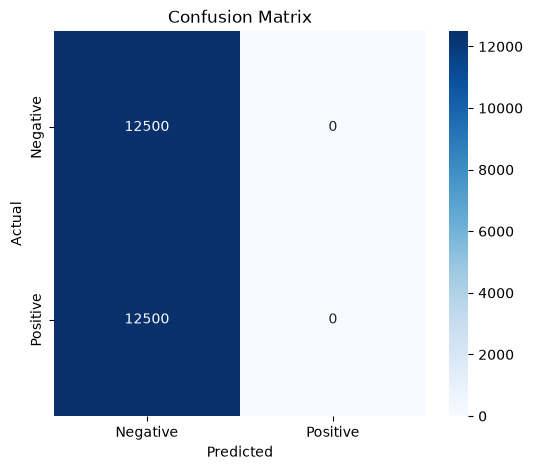

In [28]:

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

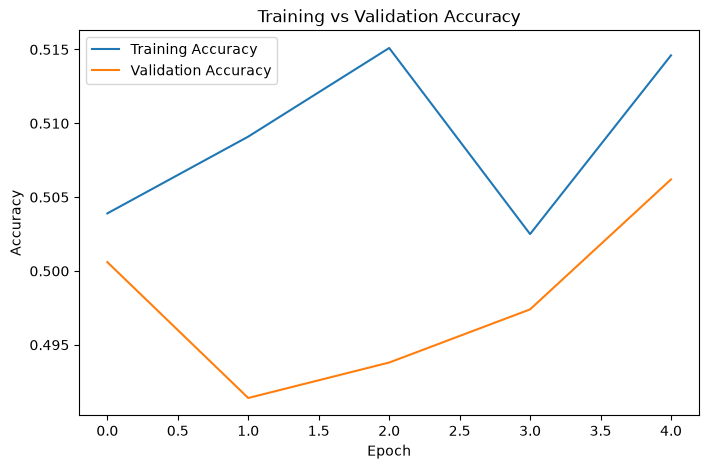

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.show()


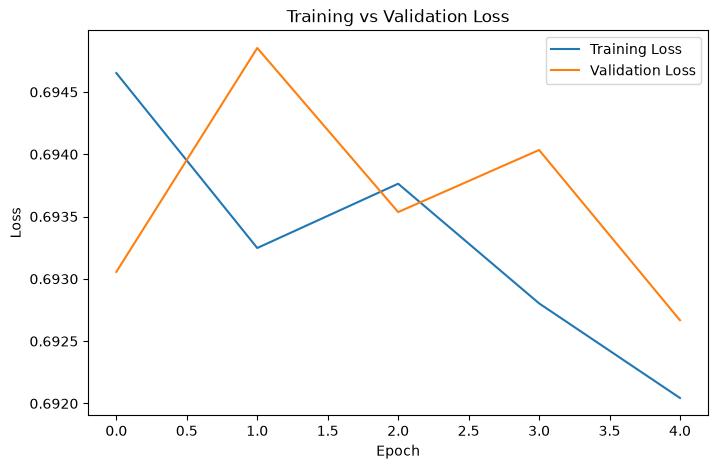

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.show()

Question 2: Data Augmentation and Analysis

In [31]:
# ============================================
# NLP DATA AUGMENTATION + PERFORMANCE ANALYSIS
# ============================================

import numpy as np
import random
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [32]:
# --------------------------------------------
# 1. Load Dataset
# --------------------------------------------

num_words = 10000

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=num_words
)

print("Original training data:", len(x_train))
print("Testing data:", len(x_test))


Original training data: 25000
Testing data: 25000


In [33]:
# --------------------------------------------
# 2. Decode IMDB Reviews
# --------------------------------------------

word_index = imdb.get_word_index()

reverse_word_index = {
    value: key for key, value in word_index.items()
}


def decode_review(review):

    words = []

    for i in review:

        if i == 0:
            continue

        elif i == 1:
            words.append("<START>")

        elif i == 2:
            words.append("<UNK>")

        else:
            words.append(
                reverse_word_index.get(
                    i - 3,
                    "<UNK>"
                )
            )

    return " ".join(words)


train_text = [
    decode_review(review)
    for review in x_train
]

test_text = [
    decode_review(review)
    for review in x_test
]


In [34]:
# --------------------------------------------
# 3. Data Augmentation
# --------------------------------------------

def random_deletion(sentence, probability=0.1):

    words = sentence.split()

    # Don't modify very short sentences
    if len(words) <= 3:
        return sentence

    new_words = []

    for word in words:

        # Randomly delete word
        if random.random() > probability:
            new_words.append(word)

    # Make sure sentence doesn't become empty
    if len(new_words) == 0:
        return random.choice(words)

    return " ".join(new_words)

In [35]:
# --------------------------------------------
# 4. Generate Augmented Dataset
# --------------------------------------------

augmented_text = []

for text in train_text:

    augmented_text.append(
        random_deletion(
            text,
            probability=0.1
        )
    )


print("\nExample Original:")
print(train_text[0])

print("\nExample Augmented:")
print(augmented_text[0])


Example Original:
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should

In [36]:
# --------------------------------------------
# 5. Tokenization
# --------------------------------------------

tokenizer = Tokenizer(
    num_words=num_words
)

# Fit on original + augmented text
tokenizer.fit_on_texts(
    train_text + augmented_text
)


In [37]:
# --------------------------------------------
# 6. Convert Text to Sequences
# --------------------------------------------

original_sequences = tokenizer.texts_to_sequences(
    train_text
)

augmented_sequences = tokenizer.texts_to_sequences(
    augmented_text
)

test_sequences = tokenizer.texts_to_sequences(
    test_text
)

In [38]:

# --------------------------------------------
# 7. Padding
# --------------------------------------------

max_length = 200

x_original = pad_sequences(
    original_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

x_augmented = pad_sequences(
    augmented_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

x_test = pad_sequences(
    test_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

In [39]:
# --------------------------------------------
# 8. Function to Create LSTM Model
# --------------------------------------------

vocab_size = num_words

def create_model():

    model = Sequential([

        Embedding(
            input_dim=vocab_size,
            output_dim=100,
            input_length=max_length
        ),

        LSTM(128),

        Dropout(0.5),

        Dense(64, activation="relu"),

        Dropout(0.5),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


In [40]:
# ============================================
# MODEL 1: ORIGINAL DATA
# ============================================

print("\n==============================")
print("TRAINING ON ORIGINAL DATA")
print("==============================")


model_original = create_model()

history_original = model_original.fit(
    x_original,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)



TRAINING ON ORIGINAL DATA


c:\Users\Devi Singh\nlp_env\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 240s 733ms/step - accuracy: 0.5068 - loss: 0.6926 - val_accuracy: 0.5566 - val_loss: 0.6846
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 229s 731ms/step - accuracy: 0.5325 - loss: 0.6893 - val_accuracy: 0.5050 - val_loss: 0.6922
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 220s 701ms/step - accuracy: 0.5789 - loss: 0.6655 - val_accuracy: 0.5760 - val_loss: 0.6605
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 225s 719ms/step - accuracy: 0.6060 - loss: 0.6472 - val_accuracy: 0.5496 - val_loss: 0.6776
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 227s 727ms/step - accuracy: 0.5976 - loss: 0.6419 - val_accuracy: 0.6152 - val_loss: 0.6537


In [41]:
# --------------------------------------------
# Evaluate Original Model
# --------------------------------------------

prob_original = model_original.predict(
    x_test
)

pred_original = (
    prob_original > 0.5
).astype(int)


original_accuracy = accuracy_score(
    y_test,
    pred_original
)

original_precision = precision_score(
    y_test,
    pred_original
)

original_recall = recall_score(
    y_test,
    pred_original
)

original_f1 = f1_score(
    y_test,
    pred_original
)



782/782 ━━━━━━━━━━━━━━━━━━━━ 133s 169ms/step


In [42]:

# ============================================
# MODEL 2: AUGMENTED DATA
# ============================================

print("\n==============================")
print("TRAINING ON AUGMENTED DATA")
print("==============================")


model_augmented = create_model()

history_augmented = model_augmented.fit(
    x_augmented,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


TRAINING ON AUGMENTED DATA


c:\Users\Devi Singh\nlp_env\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 228s 699ms/step - accuracy: 0.5145 - loss: 0.6934 - val_accuracy: 0.4950 - val_loss: 0.6939
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 221s 707ms/step - accuracy: 0.5475 - loss: 0.6860 - val_accuracy: 0.5062 - val_loss: 0.6931
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 218s 697ms/step - accuracy: 0.5323 - loss: 0.6836 - val_accuracy: 0.5496 - val_loss: 0.6803
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 221s 705ms/step - accuracy: 0.5842 - loss: 0.6484 - val_accuracy: 0.5684 - val_loss: 0.6810
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 217s 692ms/step - accuracy: 0.6051 - loss: 0.6261 - val_accuracy: 0.5800 - val_loss: 0.6920


In [43]:
prob_augmented = model_augmented.predict(
    x_test
)

pred_augmented = (
    prob_augmented > 0.5
).astype(int)


augmented_accuracy = accuracy_score(
    y_test,
    pred_augmented
)

augmented_precision = precision_score(
    y_test,
    pred_augmented
)

augmented_recall = recall_score(
    y_test,
    pred_augmented
)

augmented_f1 = f1_score(
    y_test,
    pred_augmented
)

782/782 ━━━━━━━━━━━━━━━━━━━━ 121s 153ms/step


In [44]:

# ============================================
# PERFORMANCE COMPARISON
# ============================================

print("\n========================================")
print("       PERFORMANCE COMPARISON")
print("========================================")

print(
    f"{'Metric':<15}"
    f"{'Original':<15}"
    f"{'Augmented':<15}"
)

print("-" * 45)

print(
    f"{'Accuracy':<15}"
    f"{original_accuracy:<15.4f}"
    f"{augmented_accuracy:<15.4f}"
)

print(
    f"{'Precision':<15}"
    f"{original_precision:<15.4f}"
    f"{augmented_precision:<15.4f}"
)

print(
    f"{'Recall':<15}"
    f"{original_recall:<15.4f}"
    f"{augmented_recall:<15.4f}"
)

print(
    f"{'F1 Score':<15}"
    f"{original_f1:<15.4f}"
    f"{augmented_f1:<15.4f}"
)



       PERFORMANCE COMPARISON
Metric         Original       Augmented      
---------------------------------------------
Accuracy       0.5956         0.5733         
Precision      0.6847         0.7510         
Recall         0.3545         0.2193         
F1 Score       0.4671         0.3394         


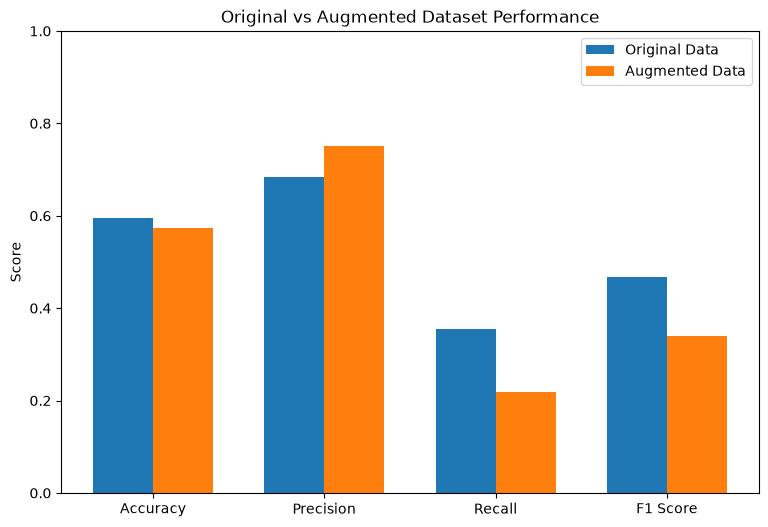

In [45]:

# ============================================
# PERFORMANCE GRAPH
# ============================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

original_scores = [
    original_accuracy,
    original_precision,
    original_recall,
    original_f1
]

augmented_scores = [
    augmented_accuracy,
    augmented_precision,
    augmented_recall,
    augmented_f1
]


x = np.arange(len(metrics))

width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width/2,
    original_scores,
    width,
    label="Original Data"
)

plt.bar(
    x + width/2,
    augmented_scores,
    width,
    label="Augmented Data"
)

plt.xticks(
    x,
    metrics
)

plt.ylabel("Score")

plt.title(
    "Original vs Augmented Dataset Performance"
)

plt.ylim(0, 1)

plt.legend()

plt.show()


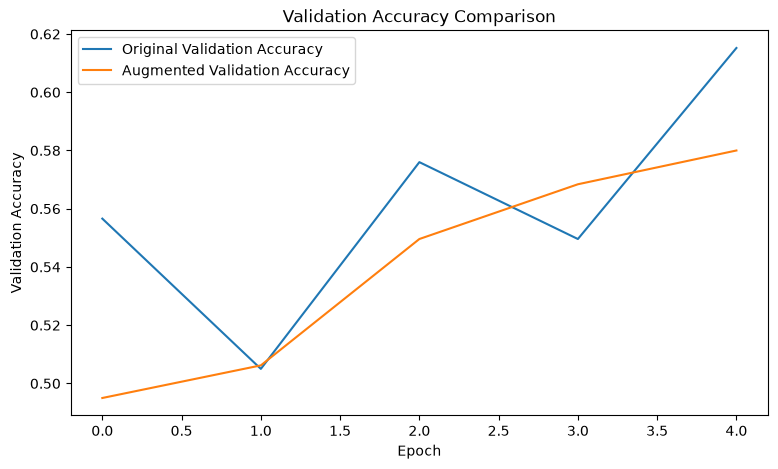

In [46]:
# ============================================
# TRAINING ACCURACY COMPARISON
# ============================================

plt.figure(figsize=(9, 5))

plt.plot(
    history_original.history["val_accuracy"],
    label="Original Validation Accuracy"
)

plt.plot(
    history_augmented.history["val_accuracy"],
    label="Augmented Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Validation Accuracy")

plt.title(
    "Validation Accuracy Comparison"
)

plt.legend()

plt.show()

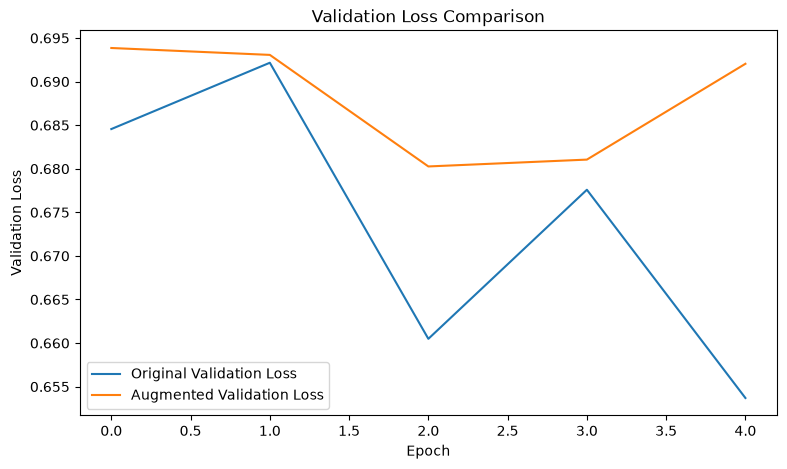

In [47]:
# ============================================
# TRAINING LOSS COMPARISON
# ============================================

plt.figure(figsize=(9, 5))

plt.plot(
    history_original.history["val_loss"],
    label="Original Validation Loss"
)

plt.plot(
    history_augmented.history["val_loss"],
    label="Augmented Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Validation Loss")

plt.title(
    "Validation Loss Comparison"
)

plt.legend()

plt.show()